<a href="https://colab.research.google.com/github/perekis228/DU/blob/main/04tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Задание 1. Закон сохранения энергии

Рассмотрим три модели запуска тела массой 1 кг вертикально вверх, которые были рассмотрены ранее. Начальные условия для моделей и полученные результаты приведены ниже.

\begin{align*}
&\text{Модель №1} && \text{Модель №2} && \text{Модель №3} \\
&\left\{
\begin{array}{l}
m \ddot h = -m g, \\
h(0) = 0, \\
\dot h(0) = 100.
\end{array}
\right.
&&
\left\{
\begin{array}{l}
m \ddot h = -m g - k \dot h, \\
h(0) = 0, \\
\dot h(0) = 100.
\end{array}
\right.
&&
\left\{
\begin{array}{l}
m \ddot h = -m g - k \dot h |\dot h|, \\
h(0) = 0, \\
\dot h(0) = 100.
\end{array}
\right.
\end{align*}

\begin{align*}
\begin{array}{l}
t_{max} = 62.5 \ \text{с}, \\
t_{back} = 125 \ \text{с}, \\
h_{max} = 3125 \ \text{м}.
\end{array}
&&
\begin{array}{l}
t_{max} \approx 48 \ \text{с}, \\
t_{back} \approx 106 \ \text{с}, \\
h_{max} \approx 2232 \ \text{м}.
\end{array}
&&
\begin{array}{l}
t_{max} \approx 11 \ \text{с}, \\
t_{back} \approx 33 \ \text{с}, \\
h_{max} \approx 207 \ \text{м}.
\end{array}
\end{align*}

В первой модели выполняется закон сохранения энергии. Тело поднимается вверх, его скорость уменьшается — кинетическая энергия падает, а потенциальная возрастает.  
Сумма кинетической и потенциальной энергий остаётся постоянной, что можно записать так:
$$E = E_k + E_p = \frac{1}{2}mv^2 + mgh,$$
где $E_k$ — кинетическая энергия, $E_p$ — потенциальная энергия, $E$ — полная механическая энергия.

В момент выстрела:
$$E = \frac{1}{2}mv_{0}^{2},$$
а в момент наивысшей точки (при $v = 0$):
$$E = mgh_{max}.$$
Из равенства этих энергий следует:
$$\displaystyle h_{max} = \frac{v_{0}^{2}}{2g} = \frac{100^2}{2 \cdot 1.6} = 3125.$$
Здесь вся кинетическая энергия полностью переходит в потенциальную — без потерь.

Первая модель представляет собой **консервативную систему**, поскольку на тело действует только одна консервативная сила, то есть сила, работа которой при перемещении тела из одной точки в другую зависит только от начального и конечного положений, но не от формы траектории.

Рассмотрим графики изменения энергии для первой модели.

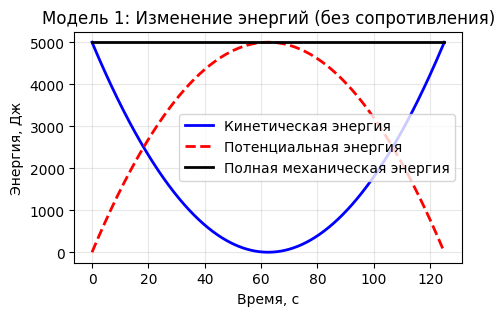

Начальная энергия: 5000.00 Дж
Максимальная полная энергия: 5000.00 Дж
Минимальная полная энергия: 5000.00 Дж


In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

# параметры
m = 1.0     # кг
g = 1.6     # м/с^2
v0 = 100.0  # начальная скорость, м/с
k = 0.01    # коэффициент линейного (квадратичного) сопротивления, кг/с (кг/м)

t = sp.Symbol('t', real=True, nonnegative=True)

t_vals = np.linspace(0, 125, 1000)

# Модель 1: без сопротивления
v1 = v0 - g * t
y1 = v0 * t - g * t**2 / 2

def f_E_kin1(t_val):
    v = v0 - g * t_val
    return 0.5 * m * v**2

def f_E_pot1(t_val):
    y = v0 * t_val - g * t_val**2 / 2
    return m * g * y

def f_E_mech1(t_val):
    return f_E_kin1(t_val) + f_E_pot1(t_val)

E_kin1_vals = [f_E_kin1(t_val) for t_val in t_vals]
E_pot1_vals = [f_E_pot1(t_val) for t_val in t_vals]
E_mech1_vals = [f_E_mech1(t_val) for t_val in t_vals]

plt.figure(figsize=(5, 3))
plt.plot(t_vals, E_kin1_vals, 'b-', label='Кинетическая энергия', linewidth=2)
plt.plot(t_vals, E_pot1_vals, 'r--', label='Потенциальная энергия', linewidth=2)
plt.plot(t_vals, E_mech1_vals, 'k-', label='Полная механическая энергия', linewidth=2)
plt.xlabel('Время, с')
plt.ylabel('Энергия, Дж')
plt.title('Модель 1: Изменение энергий (без сопротивления)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show();

# проверка сохранения энергии
print(f"Начальная энергия: {f_E_kin1(0):.2f} Дж")
print(f"Максимальная полная энергия: {np.max(E_mech1_vals):.2f} Дж")
print(f"Минимальная полная энергия: {np.min(E_mech1_vals):.2f} Дж")

Во второй и третьей моделях на тело дополнительно действует неконсервативная сила — сила сопротивления. Энергия системы не сохраняется: часть кинетической энергии расходуется на преодоление сопротивления среды, например, превращаясь в тепло, которое рассеивается в окружающем пространстве.

Найдём численно потерю энергии во втором случае.

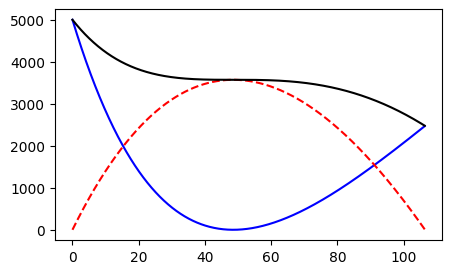

In [2]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Время интегрирования
t_full = 125
t_span = (0, t_full)
t_eval = np.linspace(0, t_full, 1001)

def model2(t, y):
    x, v = y
    return [v, -g -(k/m) * v]

# Начальные условия: h(0) = 0, v(0) = v0
y0 = [0, v0]
sol2 = solve_ivp(model2, t_span, y0, t_eval=t_eval, method='DOP853', rtol=1e-08, atol=1e-08)

# Вычисляем энергии для каждой модели
def calculate_energies(h, v):
    kinetic = 0.5 * m * v**2
    potential = m * g * h
    total = kinetic + potential
    return kinetic, potential, total

# находим индекс, где высота становится < 0
index = np.where(sol2.y[0] < 0)[0][0]
t_val = sol2.t[:index]    # здесь время
s_val = sol2.y[0][:index] # здесь путь
v_val = sol2.y[1][:index] # здесь скорость

# Энергии для модели 2
K2, P2, E2 = calculate_energies(s_val, v_val)

plt.figure(figsize=(5, 3))
plt.plot(t_val, K2, 'b')    # кинетическая энергия
plt.plot(t_val, P2, 'r--')  # потенциальная энергия
plt.plot(t_val, E2, 'k-');   # полная механическая энергия

На графике видно, что потенциальная энергия гравитации — **консервативная**, она не теряется. Потери происходят за счёт уменьшения кинетической энергии.

Можно вычислить потерю полной механической энергии во времени.

In [3]:
E0 = 0.5 * m * v0**2  # начальная кинетическая энергия
print(f"ПОТЕРИ ЭНЕРГИИ (начальная - минимальная полная): Модель 2: {E0 - np.min(E2):.2f} Дж")

ПОТЕРИ ЭНЕРГИИ (начальная - минимальная полная): Модель 2: 2522.48 Дж


---

**Задание**

Постройте графики изменения энергий для **третьей модели** и определите потерю **кинетической энергии**.  
Для оси энергий используйте **логарифмическую шкалу**: `plt.yscale('log')`.

ПОТЕРИ ЭНЕРГИИ (начальная - минимальная полная): Модель 3: 4920.66 Дж


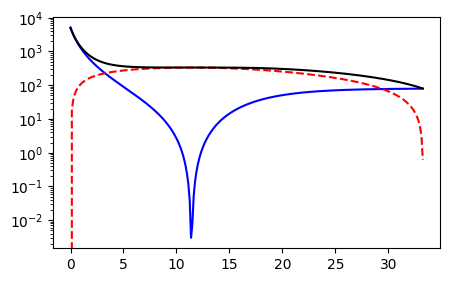

In [11]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Время интегрирования
t_full = 125
t_span = (0, t_full)
t_eval = np.linspace(0, t_full, 1001)

def model3(t, y):
    x, v = y
    return [v, -g -(k/m) * v * abs(v)]

# Начальные условия: h(0) = 0, v(0) = v0
y0 = [0, v0]
sol3 = solve_ivp(model3, t_span, y0, t_eval=t_eval, method='DOP853', rtol=1e-08, atol=1e-08)

# Вычисляем энергии для каждой модели
def calculate_energies(h, v):
    kinetic = 0.5 * m * v**2
    potential = m * g * h
    total = kinetic + potential
    return kinetic, potential, total

# находим индекс, где высота становится < 0
index = np.where(sol3.y[0] < 0)[0][0]
t_val = sol3.t[:index]    # здесь время
s_val = sol3.y[0][:index] # здесь путь
v_val = sol3.y[1][:index] # здесь скорость

# Энергии для модели 3
K3, P3, E3 = calculate_energies(s_val, v_val)

plt.figure(figsize=(5, 3))
plt.plot(t_val, K3, 'b')    # кинетическая энергия
plt.plot(t_val, P3, 'r--')  # потенциальная энергия
plt.plot(t_val, E3, 'k-');   # полная механическая энергия
plt.yscale('log')

E0 = 0.5 * m * v0**2  # начальная кинетическая энергия
print(f"ПОТЕРИ ЭНЕРГИИ (начальная - минимальная полная): Модель 3: {E0 - np.min(E3):.2f} Дж")